# Dimension 2 · Phase 1 — function results, and a toolkit for interrogating them

**Two jobs.** First, reproduce the published Phase 1 table (real change by budget function,
2025 vs 2023) from the master extract, with the FARN validation intact. Second, give you a small
set of functions for opening any function up and asking *what is actually inside this number* —
so you can hunt for reclassification artefacts yourself rather than taking my word for the two
we already found.

---

## Inputs — where this starts from

| What | Where it comes from | Required? |
|---|---|---|
| `../processed/master_2023.parquet`, `master_2025.parquet` | built by **`../scripts/00_build_master.py`** | **yes** |
| `master_2024.parquet` | same script | optional (used only for the trajectory cell) |
| INDEC CPI, annual average | fetched live from `apis.datos.gob.ar` | yes (needs internet) |
| INDEC nominal GDP | fetched live from `apis.datos.gob.ar` | only for the %-of-GDP column |

**If you have not built the master extract yet**, do that first — once, from anywhere:

```
python ../scripts/00_build_master.py
```

It downloads the annual expenditure microdata from Presupuesto Abierto, parses it once
(handling the decimal-comma trap), validates the 2023 base against FARN, and writes the
parquet files this notebook reads. Nothing here re-parses raw CSV.

This notebook **reads only**. It writes nothing except two optional CSV exports at the end,
and it never modifies the master files.

**Dependencies:** pandas, pyarrow (for parquet), matplotlib. Nothing else.

---
## 1. Setup

In [1]:
import json
import re
import ssl
import urllib.request
from pathlib import Path

import pandas as pd

MASTER_DIR = Path("../processed")
OUT_DIR = Path("../outputs")

BASE_YEAR, COMPARE_YEAR = 2023, 2025
MEASURE = "credito_devengado"          # executed / accrued spending

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 120)
pd.set_option("display.max_colwidth", 60)

SSL_CTX = ssl.create_default_context()
SSL_CTX.check_hostname = False
SSL_CTX.verify_mode = ssl.CERT_NONE
HEADERS = {"User-Agent": "Mozilla/5.0 (academic research; budget analysis)"}


def fetch(url, timeout=120):
    req = urllib.request.Request(url, headers=HEADERS)
    with urllib.request.urlopen(req, context=SSL_CTX, timeout=timeout) as r:
        return r.read()


# Columns we need. Reading a subset of a parquet file reads only those bytes.
COLS = [
    "jurisdiccion_id", "jurisdiccion_desc", "servicio_id", "servicio_desc",
    "programa_id", "programa_desc", "actividad_id", "actividad_desc",
    "finalidad_id", "finalidad_desc", "funcion_id", "funcion_desc",
    "inciso_id", "inciso_desc",
    "credito_presupuestado", "credito_vigente", "credito_devengado",
]


def load(year, cols=COLS):
    """Read one year from the master extract. Raises a clear error if it is missing."""
    for name in (f"master_{year}.parquet", f"master_{year}.csv.gz"):
        path = MASTER_DIR / name
        if path.exists():
            df = (pd.read_parquet(path, columns=cols) if path.suffix == ".parquet"
                  else pd.read_csv(path, usecols=cols, low_memory=False))
            df["anio"] = year
            return df
    raise FileNotFoundError(
        f"No master file for {year} in {MASTER_DIR.resolve()}.\n"
        "Run:  python ../scripts/00_build_master.py"
    )


D = {y: load(y) for y in (BASE_YEAR, COMPARE_YEAR)}
TOTAL = {y: D[y][MEASURE].sum() for y in D}

for y in D:
    print(f"{y}: {len(D[y]):,} rows | executed {TOTAL[y]:,.0f} millones $")

2023: 131,709 rows | executed 38,025,489 millones $
2025: 113,217 rows | executed 123,533,955 millones $


### 1.1 Deflator and GDP

CPI: series `148.3_INIVELNAL_DICI_M_26` — INDEC, national, general level, base dic-2016 = 100,
**annual average**. This is FARN's convention, which is why our real figures are comparable to
theirs.

GDP: nominal, at market prices, reconstructed as *valor agregado bruto a precios básicos*
(`8.1_VABPB_2004_A_36`) + *impuestos netos sobre los productos* (`8.1_IVA_2004_A_23`).

In [2]:
def series(ids, start="2016-12"):
    url = (f"https://apis.datos.gob.ar/series/api/series/?ids={ids}"
           f"&format=json&limit=5000&start_date={start}")
    return json.loads(fetch(url).decode("utf8"))["data"]


_cpi = pd.DataFrame(series("148.3_INIVELNAL_DICI_M_26"), columns=["fecha", "ipc"])
_cpi["fecha"] = pd.to_datetime(_cpi.fecha)
_cpi = _cpi[_cpi.fecha.dt.year.isin(D)]
assert (_cpi.groupby(_cpi.fecha.dt.year).size() == 12).all(), "incomplete CPI year"
CPI = _cpi.groupby(_cpi.fecha.dt.year)["ipc"].mean()

_g = pd.DataFrame(series("8.1_VABPB_2004_A_36,8.1_IVA_2004_A_23", "2018"),
                  columns=["fecha", "vab", "imp"])
_g["anio"] = pd.to_datetime(_g.fecha).dt.year
PIB = dict(zip(_g.anio, _g.vab + _g.imp))

DEFLATOR = CPI[COMPARE_YEAR] / CPI[BASE_YEAR]


def real(v_base, v_compare):
    """Real change between the two years. Accepts scalars or Series."""
    return (v_compare / DEFLATOR) / v_base - 1


TOTAL_REAL = real(TOTAL[BASE_YEAR], TOTAL[COMPARE_YEAR])

print(f"CPI annual average  {BASE_YEAR}: {CPI[BASE_YEAR]:,.2f}   "
      f"{COMPARE_YEAR}: {CPI[COMPARE_YEAR]:,.2f}   deflator: {DEFLATOR:.4f}")
print(f"Nominal GDP         {BASE_YEAR}: {PIB[BASE_YEAR]:,.0f}   "
      f"{COMPARE_YEAR}: {PIB[COMPARE_YEAR]:,.0f}   millones $")
print(f"\nWHOLE BUDGET, real change {COMPARE_YEAR} vs {BASE_YEAR}: {TOTAL_REAL:+.1%}")

CPI annual average  2023: 1,975.01   2025: 8,966.17   deflator: 4.5398
Nominal GDP         2023: 178,878,858   2025: 782,476,478   millones $

WHOLE BUDGET, real change 2025 vs 2023: -28.4%


---
## 2. Validation — the 2023 base must reproduce FARN

If this fails, stop: something is wrong with the extract, and nothing below can be trusted.
(`00_build_master.py` already asserts this at build time; repeating it here makes the notebook
self-contained.)

In [3]:
FARN_2023 = {1: 2_349_060, 2: 1_710_842, 3: 24_845_207, 4: 5_647_579, 5: 3_472_801}

_chk = D[BASE_YEAR].groupby("finalidad_id")[MEASURE].sum()
for fin, expected in FARN_2023.items():
    assert abs(_chk.loc[fin] - expected) < 1, f"finalidad {fin} does not match FARN"
assert abs(TOTAL[BASE_YEAR] - 38_025_489) < 1
print("PASS — 2023 reproduces FARN (2026) Table 2 to the peso.")

PASS — 2023 reproduces FARN (2026) Table 2 to the peso.


---
## 3. Reproduce the published function table

Indicators, for function $a$ with executed spending $X$, CPI $P$ and budget total $T$:

- **Real change**  $\Delta_a = \dfrac{X_{a,2025}/P_{2025}}{X_{a,2023}/P_{2023}} - 1$
- **Budget share**  $s_{a,t} = X_{a,t}/T_t$ — deflator-free
- **GDP share change** — an independent normalisation; agreement with the real change is
  evidence the result is not an artefact of the deflator
- **RRI** (Relative Retrenchment Index) $= \Delta_a - \Delta_T$, in percentage points. Negative
  means cut *more* than the state overall. This is the statistic that answers "was environment
  cut more than other areas?"

In [4]:
def funcion_table():
    w = (pd.concat(D.values())
           .groupby(["anio", "finalidad_id", "funcion_id", "funcion_desc"])[MEASURE]
           .sum().unstack("anio").fillna(0.0))
    t = pd.DataFrame(index=w.index)
    t["dev_2023"] = w[BASE_YEAR]
    t["dev_2025"] = w[COMPARE_YEAR]
    t["real_chg"] = real(w[BASE_YEAR], w[COMPARE_YEAR])
    t["share_2023_%"] = w[BASE_YEAR] / TOTAL[BASE_YEAR] * 100
    t["share_2025_%"] = w[COMPARE_YEAR] / TOTAL[COMPARE_YEAR] * 100
    pib_23 = w[BASE_YEAR] / PIB[BASE_YEAR] * 100
    pib_25 = w[COMPARE_YEAR] / PIB[COMPARE_YEAR] * 100
    t["gdpshare_chg"] = pib_25 / pib_23 - 1
    t["RRI_pp"] = (t.real_chg - TOTAL_REAL) * 100
    return t[t.dev_2023 > 0].sort_values("real_chg")


FUNCIONES = funcion_table()
FUNCIONES.reset_index().assign(rank=lambda d: range(1, len(d) + 1)) \
    .set_index(["rank", "funcion_desc"])[
        ["dev_2023", "dev_2025", "real_chg", "gdpshare_chg", "share_2023_%",
         "share_2025_%", "RRI_pp"]] \
    .style.format({"dev_2023": "{:,.0f}", "dev_2025": "{:,.0f}", "real_chg": "{:+.1%}",
                   "gdpshare_chg": "{:+.1%}", "share_2023_%": "{:.3f}",
                   "share_2025_%": "{:.3f}", "RRI_pp": "{:+.1f}"})

,,dev_2023,dev_2025,real_chg,gdpshare_chg,share_2023_%,share_2025_%,RRI_pp
rank,funcion_desc,,,,,,,
1,Vivienda y Urbanismo,"335,091","30,662",-98.0%,-97.9%,0.881,0.025,-69.5
2,Agua Potable y Alcantarillado,"423,228","165,199",-91.4%,-91.1%,1.113,0.134,-63.0
3,Industria,"121,036","103,164",-81.2%,-80.5%,0.318,0.084,-52.8
4,"Comercio, Turismo y Otros Servicios","81,244","70,171",-81.0%,-80.3%,0.214,0.057,-52.5
5,Comunicaciones,"188,322","168,988",-80.2%,-79.5%,0.495,0.137,-51.8
6,Promoción y Asistencia Social,"2,477,261","2,912,423",-74.1%,-73.1%,6.515,2.358,-45.7
7,Ecología y Desarrollo Sostenible,"119,255","191,370",-64.7%,-63.3%,0.314,0.155,-36.2
8,"Agricultura, Ganadería y Pesca","194,791","330,120",-62.7%,-61.3%,0.512,0.267,-34.2
9,Dirección Superior Ejecutiva,"179,799","305,694",-62.5%,-61.1%,0.473,0.247,-34.1


---
## 4. The exploration toolkit

Five functions. Everything below in this notebook is built from them, and so is anything you
want to try yourself.

| Function | Question it answers |
|---|---|
| `inside(f)` | what programmes/activities make up this function, in each year? |
| `trace(pattern)` | where does this programme live, and under which function, in each year? |
| `newcomers(f)` | which 2025 money sits on names that were **not in this function** in 2023? |
| `leavers(f)` | which 2023 money sat on names **absent from this function** in 2025? |
| `adjusted(f, drop)` | recompute the function's real change with some lines removed |

`newcomers` and `leavers` are the reclassification detectors: inflow and outflow of *names*.

In [5]:
def _norm(s):
    """Normalise a programme/activity name for matching: lowercase, alphanumerics only."""
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(s).lower())).strip()


def _slice(year, funcion=None, level="programa"):
    d = D[year]
    if funcion is not None:
        d = d[d.funcion_desc == funcion]
    key = f"{level}_desc"
    return d, key


def inside(funcion, level="programa", top=12, year=None):
    """What is inside a function, by programme (default) or activity, in each year."""
    years = [year] if year else list(D)
    out = {}
    for y in years:
        d, key = _slice(y, funcion, level)
        out[y] = d.groupby(key)[MEASURE].sum().sort_values(ascending=False).head(top)
    if len(years) == 1:
        return out[years[0]].to_frame(f"devengado {years[0]}")
    a, b = out[BASE_YEAR], out[COMPARE_YEAR]
    return (pd.concat([a.rename(BASE_YEAR), b.rename(COMPARE_YEAR)], axis=1)
              .fillna(0.0).sort_values(COMPARE_YEAR, ascending=False))


def trace(pattern, level="actividad", min_amount=100):
    """Follow a programme or activity by name across years, showing its function each year.

    This is how you see a reclassification: the same policy, a different `funcion_desc`.
    """
    rows = []
    for y in D:
        d = D[y]
        m = d[f"{level}_desc"].str.contains(pattern, case=False, na=False, regex=True)
        if level == "actividad":                 # also catch it named at programme level
            m |= d.programa_desc.str.contains(pattern, case=False, na=False, regex=True)
        g = (d[m].groupby(["jurisdiccion_desc", "servicio_desc", "programa_desc",
                           "actividad_desc", "funcion_desc"])[MEASURE].sum())
        g = g[g >= min_amount]
        for k, v in g.items():
            rows.append(dict(anio=y, jurisdiccion=k[0], saf=k[1], programa=k[2],
                             actividad=k[3], funcion=k[4], devengado=v))
    return (pd.DataFrame(rows).sort_values(["anio", "devengado"], ascending=[True, False])
            if rows else pd.DataFrame(columns=["anio", "funcion", "devengado"]))


def _where_before(keys, year, key, missing_label, prefix_words=5):
    """Which function did each name occupy in `year`?

    Exact name match first. Programmes are often renamed as they transfer — in 2023
    'Asistencia Financiera a Empresas Publicas ... de la Secretaria de Energia' becomes a single
    generic 'Asistencia Financiera a Empresas Publicas y Otros Entes' in 2025 — so a failed exact
    match falls back to matching on the first few words, tagged '~' to mark it as approximate.
    """
    d = D[year].assign(k=D[year][key].map(_norm))
    exact = d.groupby("k").apply(
        lambda t: t.groupby("funcion_desc")[MEASURE].sum().idxmax(), include_groups=False)

    d["p"] = d.k.str.split().str[:prefix_words].str.join(" ")
    pref = d.groupby("p").apply(
        lambda t: t.groupby("funcion_desc")[MEASURE].sum().idxmax(), include_groups=False)

    out = keys.map(exact)
    fallback = keys.str.split().str[:prefix_words].str.join(" ").map(pref)
    out = out.fillna("~ " + fallback.astype("string"))
    return out.fillna(missing_label)


def newcomers(funcion, level="programa", min_amount=0):
    """2025 money in this function whose NAME did not appear in this function in 2023.

    Either a genuinely new policy, or one relabelled into this function from elsewhere.
    `came_from` tells you which: the function it occupied in 2023, or '(new in 2025)'.
    """
    d23, key = _slice(BASE_YEAR, funcion, level)
    d25, _ = _slice(COMPARE_YEAR, funcion, level)
    had = set(d23[key].map(_norm))

    g = d25.assign(k=d25[key].map(_norm))
    g = g[~g.k.isin(had)].groupby([key, "k"])[MEASURE].sum().reset_index()
    g = g[g[MEASURE] > min_amount]

    g["came_from"] = _where_before(g.k, BASE_YEAR, key, "(new in 2025)")
    total25 = d25[MEASURE].sum()
    g["% of función 2025"] = g[MEASURE] / total25 * 100
    return (g.drop(columns="k").rename(columns={MEASURE: "devengado_2025"})
             .sort_values("devengado_2025", ascending=False).reset_index(drop=True))


def leavers(funcion, level="programa", min_amount=0):
    """2023 money in this function whose NAME is absent from this function in 2025.

    `went_to` is the function that name occupies in 2025, or '(gone)' if it vanished entirely.
    """
    d23, key = _slice(BASE_YEAR, funcion, level)
    d25, _ = _slice(COMPARE_YEAR, funcion, level)
    kept = set(d25[key].map(_norm))

    g = d23.assign(k=d23[key].map(_norm))
    g = g[~g.k.isin(kept)].groupby([key, "k"])[MEASURE].sum().reset_index()
    g = g[g[MEASURE] > min_amount]

    g["went_to"] = _where_before(g.k, COMPARE_YEAR, key, "(gone)")
    total23 = d23[MEASURE].sum()
    g["% of función 2023"] = g[MEASURE] / total23 * 100
    return (g.drop(columns="k").rename(columns={MEASURE: "devengado_2023"})
             .sort_values("devengado_2023", ascending=False).reset_index(drop=True))


def adjusted(funcion, drop=None, level="actividad", add=None):
    """Recompute a function's real change after removing and/or adding lines.

    `drop` : regex matched against the level's name in 2025 — removes that money.
    `add`  : (funcion, regex) taken from the OTHER function's 2025 rows and added in —
             used to put a migrated programme back where it came from.
    """
    v23 = D[BASE_YEAR].loc[D[BASE_YEAR].funcion_desc == funcion, MEASURE].sum()
    d25 = D[COMPARE_YEAR][D[COMPARE_YEAR].funcion_desc == funcion]
    v25 = d25[MEASURE].sum()
    removed = added = 0.0
    if drop:
        m = d25[f"{level}_desc"].str.contains(drop, case=False, na=False, regex=True)
        removed = d25.loc[m, MEASURE].sum()
        v25 -= removed
    if add:
        src_f, src_pat = add
        s = D[COMPARE_YEAR][D[COMPARE_YEAR].funcion_desc == src_f]
        m = s[f"{level}_desc"].str.contains(src_pat, case=False, na=False, regex=True)
        added = s.loc[m, MEASURE].sum()
        v25 += added
    return pd.Series({"dev_2023": v23, "dev_2025_adjusted": v25,
                      "removed": removed, "added": added,
                      "real_chg": real(v23, v25)})


print("toolkit ready:  inside() · trace() · newcomers() · leavers() · adjusted()")

toolkit ready:  inside() · trace() · newcomers() · leavers() · adjusted()


---
## 5. Worked example 1 — Trabajo at +106.5%

The published table shows función **Trabajo** growing 106.5% in real terms while the budget
fell 28.4%. Open it up.

In [6]:
inside("Trabajo", level="programa").style.format("{:,.0f}")

,2023,2025
programa_desc,,
Acciones de Empleo,"46,704","946,701"
Acciones de Articulacion Territorial,"13,257","43,312"
Actividades Centrales,"17,494","37,102"
Acciones de Capacitacion Laboral,"29,983","28,792"
Analisis y Formulacion de la Politica de Seguridad Social,544,"17,495"
Fiscalizacion Cumplimiento de la Ley de Riesgos del Trabajo,"4,145","14,001"
Formulacion y Regulacion de la Politica Laboral,"3,541","9,150"
Regularizacion del Trabajo,"1,989","6,228"


One programme, `Acciones de Empleo`, goes from ~47 thousand to ~947 thousand millones. Go one
level deeper, to activity:

In [7]:
inside("Trabajo", level="actividad", top=8).style.format("{:,.0f}")

,2023,2025
actividad_desc,,
Volver al Trabajo,0,"891,479"
Acciones de Empleo,"33,869","45,071"
Acciones de Articulacion Territorial,"13,257","43,312"
Conduccion General de la Politica Laboral y de,"14,461","36,591"
Acciones de Capacitacion,"16,724","27,696"
Conduccion y Coordinacion,"6,048","18,257"
Monotributo Social,0,"14,476"
Fiscalizacion Cumplimiento de la Ley de Riesgos del Trabajo,"4,145","14,001"
Fortalecimiento de Acciones de Orientacion Laboral y Formacion Profesional (BIRF N° 9337 - AR),"13,260",0


`Volver al Trabajo` appears from nothing and is most of the function. Where was it in 2023?

In [8]:
trace(r"Volver al Trabajo|Potenciar Trabajo|Acompa.amiento Social|Inclusion Socio",
      level="actividad", min_amount=300)

,anio,jurisdiccion,saf,programa,actividad,funcion,devengado
1,2023,Ministerio de Desarrollo Social,Ministerio de Desarrollo Social,Acciones de Pg Nac de Inclusion Socio-Productiva y Desar...,Acciones del Programa Nacional de Inclusion Socio-Produc...,Promoción y Asistencia Social,985223.933393
3,2023,Ministerio de Desarrollo Social,Ministerio de Desarrollo Social,Acciones de Pg Nac de Inclusion Socio-Productiva y Desar...,Monotributo Social (Efectores 50%) (PPG),Promoción y Asistencia Social,17721.192382
4,2023,Ministerio de Desarrollo Social,Ministerio de Desarrollo Social,Acciones de Pg Nac de Inclusion Socio-Productiva y Desar...,Monotributo Social - Potenciar Trabajo (Efectores 100%) ...,Promoción y Asistencia Social,17299.530327
2,2023,Ministerio de Desarrollo Social,Ministerio de Desarrollo Social,Acciones de Pg Nac de Inclusion Socio-Productiva y Desar...,Acciones para el Fortalecimiento y Desarrollo de las Uni...,Promoción y Asistencia Social,931.288705
0,2023,Ministerio de Desarrollo Social,Ministerio de Desarrollo Social,Acciones de Pg Nac de Inclusion Socio-Productiva y Desar...,Acciones Vinculadas al Programa de Apoyo a la Equidad y ...,Promoción y Asistencia Social,375.579210
6,2025,Ministerio de Capital Humano,"Secretaría de Trabajo, Empleo y Seguridad Social",Acciones de Empleo,Volver al Trabajo,Trabajo,891478.501915
5,2025,Ministerio de Capital Humano,"Secretaría Nacional de Niñez, Adolescencia y Familia",Acciones de Inclusion Social,Acompañamiento Social,Promoción y Asistencia Social,196778.965981


There it is. **Potenciar Trabajo** (~1,021,601 millones in 2023) sat in the Ministerio de
Desarrollo Social under función **Promoción y Asistencia Social**. In 2024 it was split into
*Volver al Trabajo* — relabelled into función **Trabajo** — and *Acompañamiento Social*, which
stayed in Promoción. Both moved to Capital Humano.

The same reclassification inflates one function and deflates the other. Quantify both, and the
combined block that is immune to the relabelling:

In [9]:
VAT = r"Volver al Trabajo"

rows = {
    "3.6 Trabajo — as published":
        adjusted("Trabajo"),
    "3.6 Trabajo — excluding Volver al Trabajo":
        adjusted("Trabajo", drop=VAT),
    "3.2 Promoción — as published":
        adjusted("Promoción y Asistencia Social"),
    "3.2 Promoción — with Volver al Trabajo put back":
        adjusted("Promoción y Asistencia Social", add=("Trabajo", VAT)),
}
block_23 = sum(D[BASE_YEAR].loc[D[BASE_YEAR].funcion_desc == f, MEASURE].sum()
               for f in ("Trabajo", "Promoción y Asistencia Social"))
block_25 = sum(D[COMPARE_YEAR].loc[D[COMPARE_YEAR].funcion_desc == f, MEASURE].sum()
               for f in ("Trabajo", "Promoción y Asistencia Social"))
rows["3.2 + 3.6 combined (reclassification-proof)"] = pd.Series(
    {"dev_2023": block_23, "dev_2025_adjusted": block_25,
     "removed": 0.0, "added": 0.0, "real_chg": real(block_23, block_25)})

pd.DataFrame(rows).T[["dev_2023", "dev_2025_adjusted", "real_chg"]] \
    .style.format({"dev_2023": "{:,.0f}", "dev_2025_adjusted": "{:,.0f}", "real_chg": "{:+.1%}"})

,dev_2023,dev_2025_adjusted,real_chg
3.6 Trabajo — as published,"117,657","1,102,782",+106.5%
3.6 Trabajo — excluding Volver al Trabajo,"117,657","211,303",-60.4%
3.2 Promoción — as published,"2,477,261","2,912,423",-74.1%
3.2 Promoción — with Volver al Trabajo put back,"2,477,261","3,803,901",-66.2%
3.2 + 3.6 combined (reclassification-proof),"2,594,919","4,015,205",-65.9%


---
## 6. Worked example 2 — Salud at +11.8%

In [10]:
inside("Salud", level="programa", top=8).style.format("{:,.0f}")

,2023,2025
programa_desc,,
Asistencia Financiera a Empresas Publicas y Otros Entes del Ministerio de Salud,0,"1,698,549"
Transferencias y Contribuciones a la Seguridad Social y Organismos Descentralizados,"384,576","1,688,733"
Atencion Medica a los Beneficiarios de Pensiones no Contributivas,"195,949","735,274"
Transferencias Varias,"120,463","543,544"
Acciones de Nutricion – Programa 1.000 Dias,0,"352,311"
Atencion Sanitaria para la Comunidad,"60,738","206,927"
Prevencion y Control de Enfermedades Transmisible e Inmunoprevenibles,0,"202,898"
Actividades Centrales,0,"151,285"
Asistencia Financiera a Agentes del Seguro de Salud,"71,780",0


A large 2025 line has no 2023 counterpart inside Salud. `newcomers` names it and says where it
was booked before:

In [11]:
newcomers("Salud", level="programa", min_amount=50_000)

,programa_desc,devengado_2025,came_from,% of función 2025
0,Asistencia Financiera a Empresas Publicas y Otros Entes ...,1.698549e+06,"~ Energía, Combustibles y Minería",24.518105
1,Prevencion y Control de Enfermedades Transmisible e Inmu...,2.028982e+05,~ Salud,2.928782
2,Fortalecimiento de los Sistemas Provinciales de Salud,1.220572e+05,(new in 2025),1.761863
3,Cobertura Sanitaria Compensatoria,1.127729e+05,(new in 2025),1.627846


`Asistencia Financiera a Empresas Públicas y Otros Entes` was spread across Energía, Transporte,
Agua and Promoción Social in 2023, with **nothing** in Salud. Remove it and Salud is not growth:

In [12]:
pd.DataFrame({
    "Salud — as published": adjusted("Salud"),
    "Salud — excl. Asistencia Financiera a Empresas Públicas":
        adjusted("Salud", drop=r"Asistencia Financiera a Empresas", level="programa"),
}).T[["dev_2023", "dev_2025_adjusted", "removed", "real_chg"]] \
  .style.format({"dev_2023": "{:,.0f}", "dev_2025_adjusted": "{:,.0f}",
                 "removed": "{:,.0f}", "real_chg": "{:+.1%}"})

,dev_2023,dev_2025_adjusted,removed,real_chg
Salud — as published,"1,364,710","6,927,734",0,+11.8%
Salud — excl. Asistencia Financiera a Empresas Públicas,"1,364,710","5,229,185","1,698,549",-15.6%


---
## 7. Screen every function for the same problem

Rather than checking functions one at a time, measure the exposure of all of them at once.

- **inflow %** — share of a function's 2025 money sitting on programme names that were **not in
  that function** in 2023.
- **outflow %** — share of its 2023 money on names **absent from it** in 2025.

High inflow means the headline is inflated by relabelling; high outflow means it is deflated.
Low on both means the published figure can be read at face value. Treat this as a triage tool,
not a verdict: a renamed-but-unmoved programme registers as both, so anything flagged needs
eyeballing with `newcomers()` / `leavers()` before you conclude anything.

In [13]:
def exposure_screen(level="programa"):
    rows = []
    for f in FUNCIONES.index.get_level_values("funcion_desc"):
        d23 = D[BASE_YEAR][D[BASE_YEAR].funcion_desc == f]
        d25 = D[COMPARE_YEAR][D[COMPARE_YEAR].funcion_desc == f]
        k = f"{level}_desc"
        n23, n25 = set(d23[k].map(_norm)), set(d25[k].map(_norm))
        t23, t25 = d23[MEASURE].sum(), d25[MEASURE].sum()
        inflow = d25.loc[~d25[k].map(_norm).isin(n23), MEASURE].sum()
        outflow = d23.loc[~d23[k].map(_norm).isin(n25), MEASURE].sum()
        rows.append({"funcion_desc": f,
                     "real_chg": FUNCIONES.xs(f, level="funcion_desc").real_chg.iloc[0],
                     "inflow_%": inflow / t25 * 100 if t25 else 0.0,
                     "outflow_%": outflow / t23 * 100 if t23 else 0.0,
                     "dev_2023": t23})
    out = pd.DataFrame(rows).set_index("funcion_desc")
    out["max_exposure_%"] = out[["inflow_%", "outflow_%"]].max(axis=1)
    return out.sort_values("max_exposure_%", ascending=False)


EXPOSURE = exposure_screen()
EXPOSURE.style.format({"real_chg": "{:+.1%}", "inflow_%": "{:.1f}", "outflow_%": "{:.1f}",
                       "max_exposure_%": "{:.1f}", "dev_2023": "{:,.0f}"}) \
    .background_gradient(subset=["max_exposure_%"], cmap="Oranges")

,real_chg,inflow_%,outflow_%,dev_2023,max_exposure_%
funcion_desc,,,,,
Transporte,-58.5%,76.7,70.2,"1,696,743",76.7
"Comercio, Turismo y Otros Servicios",-81.0%,62.9,11.9,"81,244",62.9
Agua Potable y Alcantarillado,-91.4%,22.2,51.0,"423,228",51.0
Relaciones Interiores,-53.1%,49.8,32.5,"947,480",49.8
Promoción y Asistencia Social,-74.1%,13.9,46.5,"2,477,261",46.5
Dirección Superior Ejecutiva,-62.5%,12.9,43.3,"179,799",43.3
Comunicaciones,-80.2%,37.3,24.1,"188,322",37.3
Ecología y Desarrollo Sostenible,-64.7%,35.2,16.1,"119,255",35.2
Salud,+11.8%,31.6,8.4,"1,364,710",31.6


### How to use this

Pick any row with high exposure and interrogate it:

```python
newcomers("Energía, Combustibles y Minería", min_amount=50_000)   # what arrived
leavers("Ecología y Desarrollo Sostenible", min_amount=1_000)     # what left
inside("Transporte", level="actividad", top=20)                   # what is in it
trace(r"your programme name")                                     # follow one policy
adjusted("Some función", drop=r"name to exclude")                 # recompute without it
```

The focal functions for the paper — **Ecología y Desarrollo Sostenible** and **Ciencia,
Tecnología e Innovación** — are worth checking first, since they carry the argument:

In [14]:
EXPOSURE.loc[["Ecología y Desarrollo Sostenible", "Ciencia, Tecnología e Innovación",
              "Educación y Cultura", "Inteligencia"]] \
    .style.format({"real_chg": "{:+.1%}", "inflow_%": "{:.1f}", "outflow_%": "{:.1f}",
                   "max_exposure_%": "{:.1f}", "dev_2023": "{:,.0f}"})

,real_chg,inflow_%,outflow_%,dev_2023,max_exposure_%
funcion_desc,,,,,
Ecología y Desarrollo Sostenible,-64.7%,35.2,16.1,"119,255",35.2
"Ciencia, Tecnología e Innovación",-43.9%,0.2,0.0,"577,409",0.2
Educación y Cultura,-47.2%,8.0,16.7,"2,757,050",16.7
Inteligencia,-4.4%,0.0,0.0,"64,454",0.0


In [15]:
leavers("Ecología y Desarrollo Sostenible", level="actividad", min_amount=500)

,actividad_desc,devengado_2023,went_to,% of función 2023


### The blind spot you must know about

`newcomers` and `leavers` compare **sets of names**. They therefore cannot see a *partial*
migration — where a policy is split and the same name exists in two functions at once. That is
exactly what happened to fire management, so it is invisible to the screen above and has to be
found with `trace`:

In [16]:
trace(r"Servicio Nacional de Manejo del Fuego", level="actividad", min_amount=100)

,anio,jurisdiccion,saf,programa,actividad,funcion,devengado
0,2023,Ministerio de Ambiente y Desarrollo Sostenible,Ministerio de Ambiente y Desarrollo Sostenible,Control Ambiental,Servicio Nacional de Manejo del Fuego,Ecología y Desarrollo Sostenible,12099.566140
2,2025,Ministerio de Seguridad Nacional,Ministerio de Seguridad Nacional,Acciones ante Desastres y Emergencias de Origen Socio-Na...,Servicio Nacional de Manejo del Fuego,Seguridad Interior,43912.970147
1,2025,Jefatura de Gabinete de Ministros,Ambiente,Control Ambiental,Servicio Nacional de Manejo del Fuego,Ecología y Desarrollo Sostenible,16055.474197


In 2023 the Servicio Nacional de Manejo del Fuego sat entirely inside the environment area. By
2025 most of it is executed by the Ministerio de Seguridad under a different function, with a
residue still booked to Ecología. The name never disappeared from Ecología, so no set-difference
test flags it.

**Practical rule:** use the exposure screen to find candidates fast, then `trace` anything whose
size makes it material. A function can look clean on the screen and still have lost or gained a
large policy through a split.

---
## 8. A reclassification-adjusted version of Figure 1

The published figure plots the classifier as the government wrote it. That is the right default —
it is what FARN computes and what any replicator will get — but §5–7 showed that at least three
lines make some functions non-comparable between 2023 and 2025. This section builds an
**adjusted** figure alongside it, so the paper can report both and say which claims survive.

### The rule set

Every correction is one of two kinds, and each is declared as data rather than hard-coded, with
its evidence attached. Nothing is adjusted unless it can be pointed at.

| Kind | What it does | When it is the right move |
|---|---|---|
| **`move`** | reassigns a 2025 line to the function its antecedent occupied in 2023 | the policy is identifiable in both years and simply changed label |
| **`exclude_arrivals`** | drops a family of lines from the later year, but **only in the functions where it had no base-year presence** | the family is legitimate spending where it recurs, and non-comparable only where it newly appears |
| **`exclude`** | drops a family of lines from **both** years, everywhere | nothing about the line is comparable anywhere — the blunt last resort |

`move` restores a constant perimeter. `exclude_arrivals` is the surgical version of exclusion:
it removes a line only where it has no base-year counterpart, which is precisely where the
comparison is broken, and leaves it alone where it recurs legitimately. The blunt `exclude`
remains available but is a last resort — see the coverage warning below for why. The whole-budget
benchmark is recomputed after any exclusion, so the dashed reference line stays consistent with
the bars.

**The moves cut both ways.** Returning fire management to Ecología makes the environmental cut
*smaller*, not larger. That is the point of doing this properly rather than only correcting the
artefacts that flatter the argument.

In [17]:
ADJUSTMENTS = [
    dict(kind="move", level="actividad",
         pattern=r"Volver al Trabajo",
         source="Trabajo", target="Promoción y Asistencia Social",
         note="ex-Potenciar Trabajo: in 2023 it was 'Acciones del Pg Nac de Inclusión "
              "Socio-Productiva' in Desarrollo Social, función Promoción y Asistencia Social. "
              "Split in 2024 into Volver al Trabajo (relabelled to Trabajo) and Acompañamiento "
              "Social (stayed in Promoción). See §5."),

    dict(kind="move", level="actividad",
         pattern=r"Servicio Nacional de Manejo del Fuego",
         source="Seguridad Interior", target="Ecología y Desarrollo Sostenible",
         note="SNMF sat entirely inside SAF 317 (Ambiente) in 2023. Transferred to the Ministerio "
              "de Seguridad in Feb 2025 (BO 12/02/2025); a residue stays in Ecología, so this is a "
              "partial migration invisible to the name-set screen. See §7."),

    dict(kind="exclude_arrivals", level="programa",
         pattern=r"Asistencia Financiera a Empresas",
         note="Treasury support to state enterprises. It is legitimately part of several functions "
              "in BOTH years — 88% of Comunicaciones in 2023, and large blocks in Energía and "
              "Transporte — so removing it everywhere would delete real spending. It is only "
              "non-comparable where it ARRIVES with no 2023 antecedent in that function, which is "
              "Salud (0 in 2023, 1,698,549 in 2025). This rule drops it only from those functions. "
              "See §6."),
]

pd.DataFrame(ADJUSTMENTS)[["kind", "level", "pattern", "source", "target", "note"]] \
    .fillna("—").style.set_properties(**{"white-space": "normal", "text-align": "left"})

,kind,level,pattern,source,target,note
0,move,actividad,Volver al Trabajo,Trabajo,Promoción y Asistencia Social,"ex-Potenciar Trabajo: in 2023 it was 'Acciones del Pg Nac de Inclusión Socio-Productiva' in Desarrollo Social, función Promoción y Asistencia Social. Split in 2024 into Volver al Trabajo (relabelled to Trabajo) and Acompañamiento Social (stayed in Promoción). See §5."
1,move,actividad,Servicio Nacional de Manejo del Fuego,Seguridad Interior,Ecología y Desarrollo Sostenible,"SNMF sat entirely inside SAF 317 (Ambiente) in 2023. Transferred to the Ministerio de Seguridad in Feb 2025 (BO 12/02/2025); a residue stays in Ecología, so this is a partial migration invisible to the name-set screen. See §7."
2,exclude_arrivals,programa,Asistencia Financiera a Empresas,—,—,"Treasury support to state enterprises. It is legitimately part of several functions in BOTH years — 88% of Comunicaciones in 2023, and large blocks in Energía and Transporte — so removing it everywhere would delete real spending. It is only non-comparable where it ARRIVES with no 2023 antecedent in that function, which is Salud (0 in 2023, 1,698,549 in 2025). This rule drops it only from those functions. See §6."


### Applying them

`apply_adjustments` returns a *new* pair of year frames. The originals in `D` are untouched, so
every earlier cell keeps producing the published numbers.

In [18]:
def apply_adjustments(adjustments=ADJUSTMENTS, verbose=True):
    """Return adjusted copies of the year frames, plus a log of what each rule did."""
    A = {y: D[y].copy() for y in D}
    log = []

    for rule in adjustments:
        key = f"{rule['level']}_desc"

        if rule["kind"] == "exclude_arrivals":
            # Drop the matching lines ONLY from functions where they have no base-year presence.
            # Where the family exists in both years it is correctly classified and is left alone —
            # deleting it would remove real spending and measure the function on a remnant.
            thresh = rule.get("threshold_pct_of_base", 1.0)
            base = A[BASE_YEAR]
            bm = base[key].str.contains(rule["pattern"], case=False, na=False, regex=True)
            base_by_f = base[bm].groupby("funcion_desc")[MEASURE].sum()
            fun_total_23 = base.groupby("funcion_desc")[MEASURE].sum()
            share = (base_by_f / fun_total_23 * 100).reindex(fun_total_23.index).fillna(0.0)
            orphan_funcs = set(share[share < thresh].index)

            y = COMPARE_YEAR
            m = (A[y][key].str.contains(rule["pattern"], case=False, na=False, regex=True)
                 & A[y].funcion_desc.isin(orphan_funcs))
            amount = A[y].loc[m, MEASURE].sum()
            hit = sorted(A[y].loc[m, "funcion_desc"].unique())
            A[y] = A[y][~m]
            log.append({"rule": rule["pattern"], "kind": "exclude_arrivals",
                        "from": ", ".join(hit) or "(none)",
                        "to": f"(removed from {COMPARE_YEAR} only, where absent in {BASE_YEAR})",
                        "amount": amount})

        elif rule["kind"] == "exclude":
            moved = 0.0
            for y in A:
                m = A[y][key].str.contains(rule["pattern"], case=False, na=False, regex=True)
                moved += A[y].loc[m, MEASURE].sum()
                A[y] = A[y][~m]
            log.append({"rule": rule["pattern"], "kind": "exclude",
                        "from": "(all functions)", "to": "(removed, both years)",
                        "amount": moved})

        elif rule["kind"] == "move":
            y = COMPARE_YEAR                      # only the later year is relabelled
            m = A[y][key].str.contains(rule["pattern"], case=False, na=False, regex=True)
            if rule.get("source"):
                m &= A[y].funcion_desc == rule["source"]
            amount = A[y].loc[m, MEASURE].sum()
            A[y].loc[m, "funcion_desc"] = rule["target"]
            log.append({"rule": rule["pattern"], "kind": "move",
                        "from": rule.get("source", "(any)"), "to": rule["target"],
                        "amount": amount})
        else:
            raise ValueError(f"unknown adjustment kind: {rule['kind']}")

    log = pd.DataFrame(log)
    if verbose:
        print(log.to_string(index=False, float_format=lambda v: f"{v:,.0f}"))
    return A, log


ADJ, ADJ_LOG = apply_adjustments()

ADJ_TOTAL = {y: ADJ[y][MEASURE].sum() for y in ADJ}
ADJ_TOTAL_REAL = real(ADJ_TOTAL[BASE_YEAR], ADJ_TOTAL[COMPARE_YEAR])
print(f"\nwhole budget, published: {TOTAL_REAL:+.2%}   adjusted: {ADJ_TOTAL_REAL:+.2%}   "
      f"(the exclusion removes {TOTAL[BASE_YEAR]-ADJ_TOTAL[BASE_YEAR]:,.0f} from {BASE_YEAR} "
      f"and {TOTAL[COMPARE_YEAR]-ADJ_TOTAL[COMPARE_YEAR]:,.0f} from {COMPARE_YEAR})")

                                 rule             kind                                                         from                                             to    amount
                    Volver al Trabajo             move                                                      Trabajo                  Promoción y Asistencia Social   891,479
Servicio Nacional de Manejo del Fuego             move                                           Seguridad Interior               Ecología y Desarrollo Sostenible    43,913
     Asistencia Financiera a Empresas exclude_arrivals Ciencia, Tecnología e Innovación, Educación y Cultura, Salud (removed from 2025 only, where absent in 2023) 1,811,226

whole budget, published: -28.44%   adjusted: -29.49%   (the exclusion removes 0 from 2023 and 1,811,226 from 2025)


**Note the `funcion_id` caveat.** A moved line keeps its original `funcion_id` while acquiring a
new `funcion_desc`, so the adjusted table is keyed on the description only. That is deliberate:
the id belongs to the government's classification and should not be rewritten.

In [19]:
def adjusted_funcion_table(frames=None, total=None, total_real=None):
    frames = frames or ADJ
    total = total or ADJ_TOTAL
    total_real = ADJ_TOTAL_REAL if total_real is None else total_real
    w = (pd.concat(frames.values())
           .groupby(["anio", "funcion_desc"])[MEASURE].sum().unstack("anio").fillna(0.0))
    t = pd.DataFrame(index=w.index)
    t["dev_2023"] = w[BASE_YEAR]
    t["dev_2025"] = w[COMPARE_YEAR]
    t["real_chg"] = real(w[BASE_YEAR], w[COMPARE_YEAR])
    t["share_2023_%"] = w[BASE_YEAR] / total[BASE_YEAR] * 100
    t["share_2025_%"] = w[COMPARE_YEAR] / total[COMPARE_YEAR] * 100
    t["RRI_pp"] = (t.real_chg - total_real) * 100
    return t[t.dev_2023 > 0].sort_values("real_chg")


ADJUSTED = adjusted_funcion_table()

### Published vs adjusted — what actually moves

In [20]:
pub = FUNCIONES.reset_index().set_index("funcion_desc")
cmp = pd.DataFrame({
    "published": pub.real_chg,
    "adjusted": ADJUSTED.real_chg,
}).dropna()
cmp["delta_pp"] = (cmp.adjusted - cmp.published) * 100
cmp["rank_published"] = cmp.published.rank(method="min").astype(int)
cmp["rank_adjusted"] = cmp.adjusted.rank(method="min").astype(int)
cmp["rank_move"] = cmp.rank_published - cmp.rank_adjusted

# How much of each function's 2023 base survives the exclusion? A function that loses most of its
# base is being measured on a remnant, and its adjusted figure should not be trusted — see below.
cmp["retained_2023_%"] = (ADJUSTED.dev_2023 / pub.dev_2023 * 100).reindex(cmp.index)
LOW_COVERAGE = cmp["retained_2023_%"] < 70

CHANGED = cmp[cmp.delta_pp.abs() > 0.05].sort_values("delta_pp")
print(f"{len(CHANGED)} of {len(cmp)} functions change; the other "
      f"{len(cmp) - len(CHANGED)} are identical.\n")
CHANGED.style.format({"published": "{:+.1%}", "adjusted": "{:+.1%}", "delta_pp": "{:+.1f}",
                      "rank_move": "{:+d}", "retained_2023_%": "{:.0f}"}) \
    .apply(lambda r: ["background-color: #fdece4" if r["retained_2023_%"] < 70 else ""
                      for _ in r], axis=1)

6 of 29 functions change; the other 23 are identical.



,published,adjusted,delta_pp,rank_published,rank_adjusted,rank_move,retained_2023_%
funcion_desc,,,,,,,
Trabajo,+106.5%,-60.4%,-166.9,29,9,+20,100
Salud,+11.8%,-15.6%,-27.4,28,26,+2,100
Seguridad Interior,-26.3%,-27.4%,-1.1,21,21,+0,100
Educación y Cultura,-47.2%,-48.1%,-0.9,13,14,-1,100
Promoción y Asistencia Social,-74.1%,-66.2%,+7.9,6,6,+0,100
Ecología y Desarrollo Sostenible,-64.7%,-56.5%,+8.1,7,12,-5,100


### The cost of the `exclude` rule — read this before using the adjusted numbers

Removing a line from **both** years is unbiased, but it is not free: it shrinks the base a
function is measured on. `Asistencia Financiera a Empresas Públicas` was a large share of some
small functions' 2023 spending, so excluding it leaves them measured on a remnant, and their
adjusted percentage swings wildly on a tiny denominator.

`retained_2023_%` is the diagnostic. Functions below 70% (shaded above, and marked `*` in the
figure) are **not** better measured by the adjusted figure — for those, the published number is
the more meaningful one and the honest report is "not comparable across the reclassification".

This is why the adjusted figure is a robustness check rather than a replacement.

In [21]:
cmp.loc[LOW_COVERAGE, ["published", "adjusted", "retained_2023_%"]] \
   .sort_values("retained_2023_%") \
   .style.format({"published": "{:+.1%}", "adjusted": "{:+.1%}", "retained_2023_%": "{:.0f}"})

,published,adjusted,retained_2023_%
funcion_desc,,,


### The figure

Same form as the published Figure 1 so the two are directly comparable: bars are the **adjusted**
real change; where a function moved, a hollow marker shows where it sat in the published version,
joined by a thin connector. Functions that did not move carry no marker, which keeps the eye on
the handful that did.

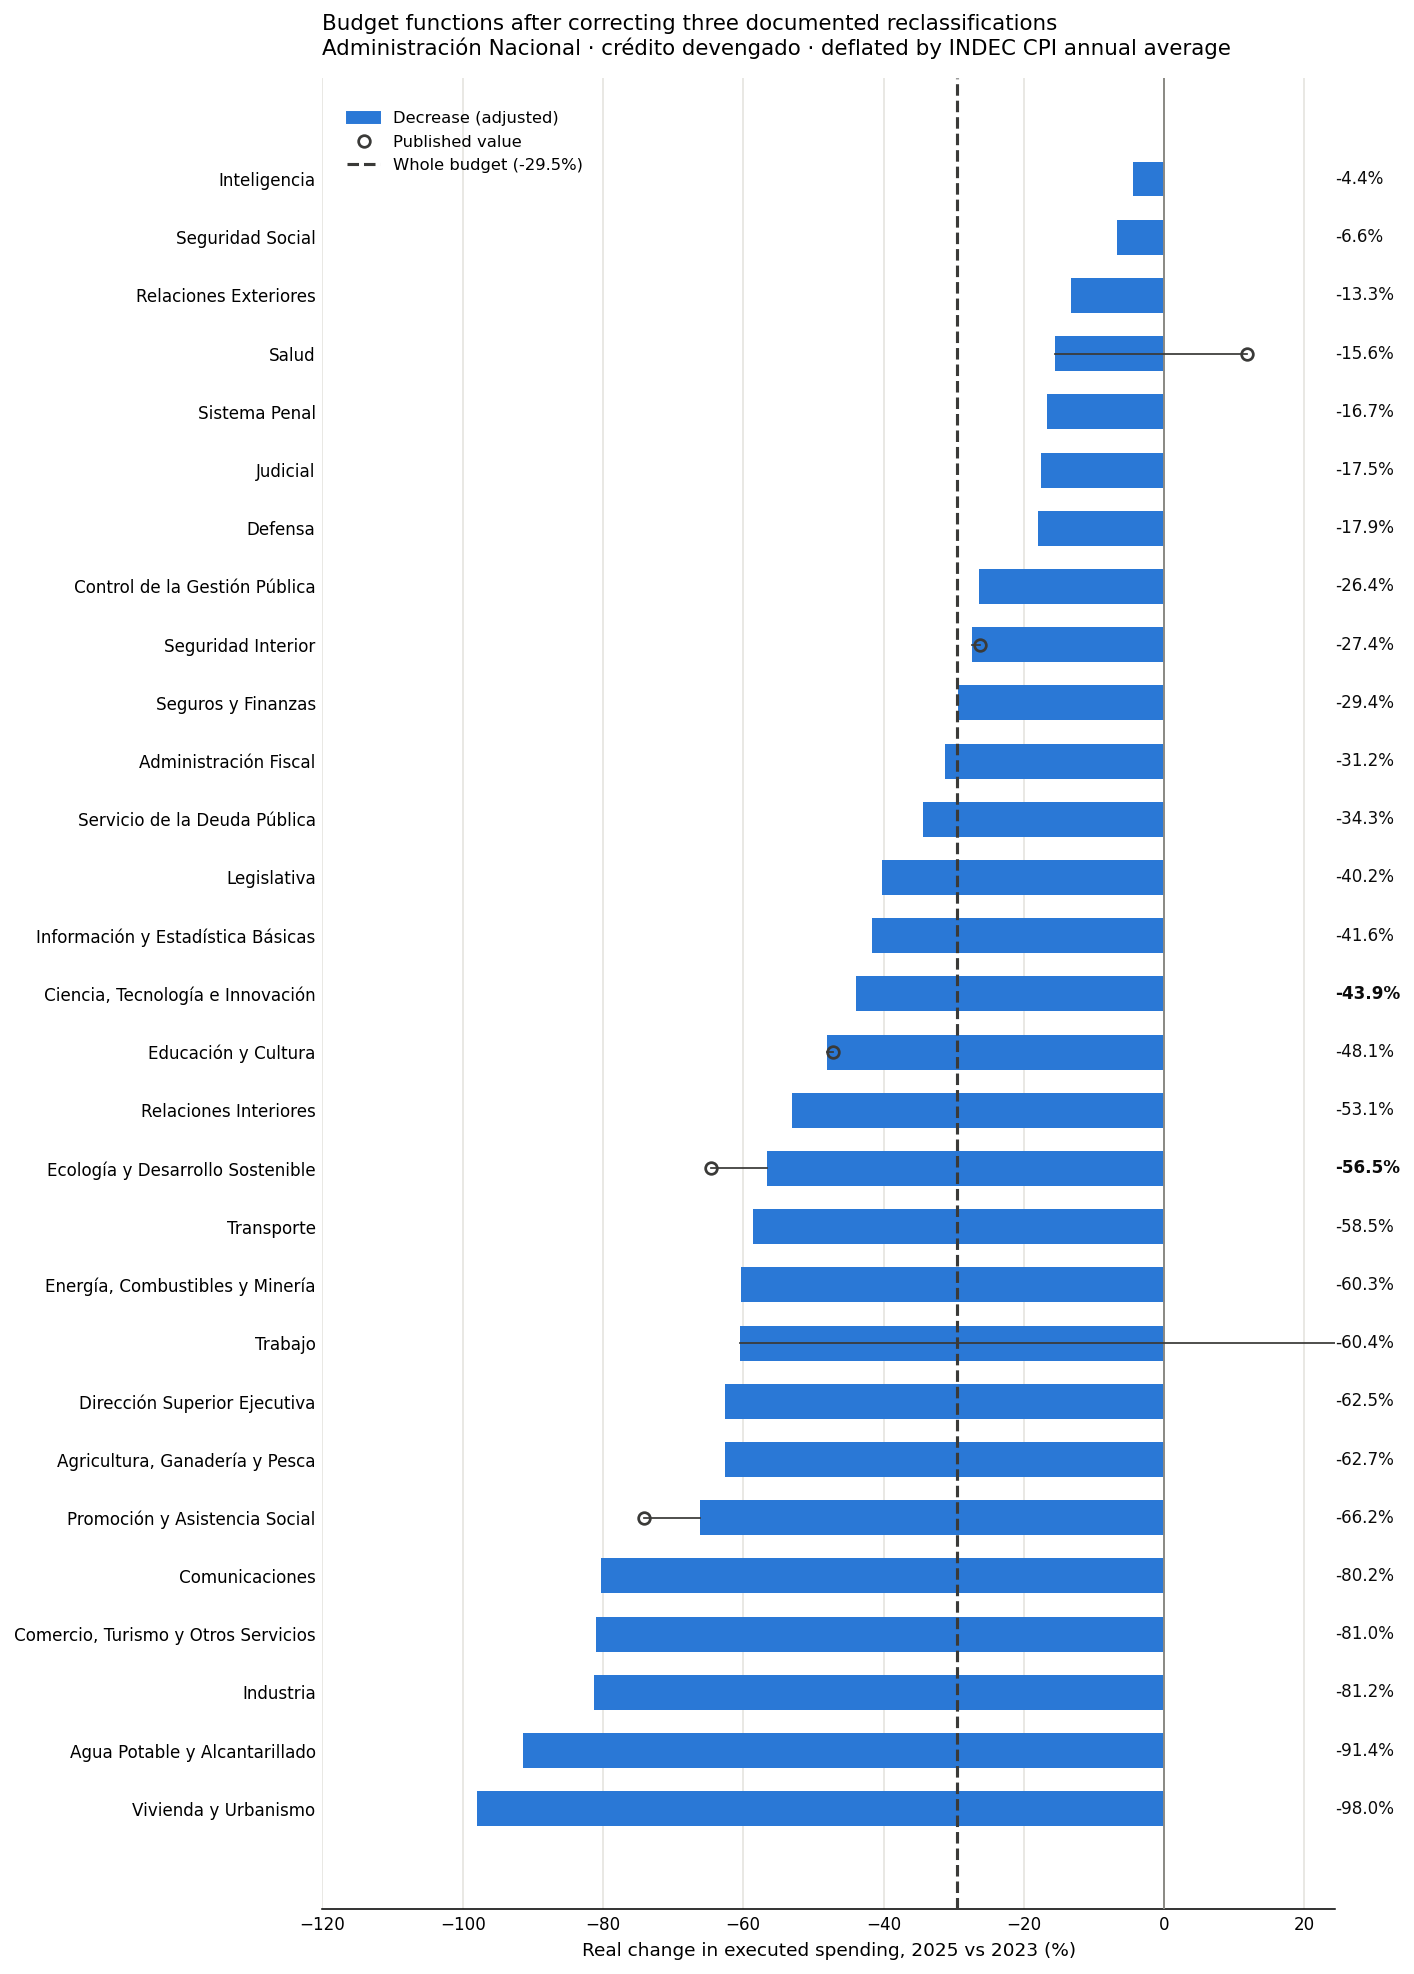

In [22]:
import matplotlib.pyplot as plt

FOCAL = {"Ecología y Desarrollo Sostenible", "Ciencia, Tecnología e Innovación"}
C_CUT, C_RISE, C_PUB = "#2a78d6", "#eb6834", "#8a8984"   # validated palette, light surface

def plot_adjusted(save_as="fig1b_funcion_real_change_adjusted.png"):
    p = cmp.sort_values("adjusted")
    lo = min(-100, p.adjusted.min() * 100 - 6)
    hi = max(20, p.adjusted.max() * 100 + 6)
    label_x = hi + (hi - lo) * 0.035

    fig, ax = plt.subplots(figsize=(10.2, 0.40 * len(p) + 2.6), dpi=140)
    ax.barh(p.index, p.adjusted * 100, height=0.60, zorder=3,
            color=[C_RISE if v > 0 else C_CUT for v in p.adjusted])
    ax.axvline(0, color="#8a8984", lw=1, zorder=4)
    ax.axvline(ADJ_TOTAL_REAL * 100, color="#3a3a38", lw=1.6, ls="--", zorder=5)

    for y_, name in enumerate(p.index):
        pubv, adjv = p.published[name] * 100, p.adjusted[name] * 100
        if abs(adjv - pubv) > 0.05:
            ax.plot([pubv, adjv], [y_, y_], color="#3a3a38", lw=0.9, zorder=6)
            ax.plot([pubv], [y_], marker="o", ms=6, mfc="none", mec="#3a3a38",
                    mew=1.4, zorder=7)
        flag = "*" if LOW_COVERAGE.get(name, False) else ""
        ax.text(label_x, y_, f"{adjv:+.1f}%{flag}", va="center", ha="left", fontsize=8.6,
                color="#7a7975" if flag else "#0b0b0b",
                fontweight="bold" if name in FOCAL else "normal")

    ax.set_xlim(lo, label_x)
    ax.set_xticks(range(int(lo // 20 * 20), int(hi) + 1, 20))
    ax.set_xlabel("Real change in executed spending, 2025 vs 2023 (%)", fontsize=9.5)
    ax.set_title("Budget functions after correcting three documented reclassifications\n"
                 "Administración Nacional · crédito devengado · deflated by INDEC CPI annual average",
                 fontsize=11, loc="left", pad=12)
    n_low = int(LOW_COVERAGE.sum())
    if n_low:
        fig.text(0.01, -0.012,
                 f"*  {n_low} functions retain under 70% of their 2023 base after the exclusion; "
                 "their adjusted figure rests on a remnant and the published value is the more "
                 "meaningful one.",
                 fontsize=8, color="#52514e", ha="left")
    handles = [plt.Rectangle((0, 0), 1, 1, color=C_CUT)]
    labels = ["Decrease (adjusted)"]
    if (p.adjusted > 0).any():                 # only label a colour that is actually on screen
        handles.append(plt.Rectangle((0, 0), 1, 1, color=C_RISE))
        labels.append("Increase (adjusted)")
    handles += [plt.Line2D([0], [0], marker="o", ms=6, mfc="none", mec="#3a3a38",
                           mew=1.4, ls="none"),
                plt.Line2D([0], [0], color="#3a3a38", lw=1.6, ls="--")]
    labels += ["Published value", f"Whole budget ({ADJ_TOTAL_REAL:+.1%})"]
    ax.legend(handles, labels, fontsize=8.4, frameon=False,
              loc="upper left", bbox_to_anchor=(0.01, 0.99))
    ax.grid(axis="x", color="#e3e2dd", zorder=0)
    ax.set_axisbelow(True)
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax.tick_params(labelsize=8.6, length=0)
    plt.tight_layout()
    if save_as:
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        plt.savefig(OUT_DIR / save_as, dpi=300, bbox_inches="tight")
    plt.show()


plot_adjusted()

In [23]:
n_up_pub = int((cmp.published > 0).sum())
n_up_adj = int((cmp.adjusted > 0).sum())
print(f"Functions showing real GROWTH 2025 vs 2023 — published: {n_up_pub}   adjusted: {n_up_adj}")
print(f"Ecología: {cmp.loc['Ecología y Desarrollo Sostenible','published']:+.1%} → "
      f"{cmp.loc['Ecología y Desarrollo Sostenible','adjusted']:+.1%} "
      f"(rank {cmp.loc['Ecología y Desarrollo Sostenible','rank_published']} → "
      f"{cmp.loc['Ecología y Desarrollo Sostenible','rank_adjusted']} of {len(cmp)}), "
      f"benchmark {ADJ_TOTAL_REAL:+.1%}")
print(f"Ciencia:  {cmp.loc['Ciencia, Tecnología e Innovación','published']:+.1%} → "
      f"{cmp.loc['Ciencia, Tecnología e Innovación','adjusted']:+.1%}  (unchanged if equal)")

Functions showing real GROWTH 2025 vs 2023 — published: 2   adjusted: 0
Ecología: -64.7% → -56.5% (rank 7 → 12 of 29), benchmark -29.5%
Ciencia:  -43.9% → -43.9%  (unchanged if equal)


### How to read it in the paper

Report the **published** figure as the headline and this one as a robustness check, with a
sentence naming the three corrections and their direction. The claims to check against it:

- Does Ecología stay far below the whole-budget line? (its position is what carries the argument)
- Does the selectivity contrast — coercive core protected, environmental and epistemic capacity
  cut — survive?
- Do any of the two apparent *increases* survive as increases?
- Is the function you are quoting marked `*`? If so, quote the published figure instead.

Anything that flips between the two figures cannot be claimed without qualification. Anything
stable in both is safe to state plainly.

### Extending the rule set

Add a dict to `ADJUSTMENTS` and re-run from that cell. Before adding one, satisfy yourself with
`trace()` that the line really is the same policy in both years, and write the evidence into
`note` — the rule set doubles as the audit trail the methods annex will need.

---
## 9. Optional export

In [24]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
FUNCIONES.to_csv(OUT_DIR / "explorer_funcion_table.csv")
EXPOSURE.to_csv(OUT_DIR / "explorer_reclassification_exposure.csv")
ADJUSTED.to_csv(OUT_DIR / "explorer_funcion_table_adjusted.csv")
cmp.to_csv(OUT_DIR / "explorer_published_vs_adjusted.csv")
ADJ_LOG.to_csv(OUT_DIR / "explorer_adjustment_log.csv", index=False)
print("wrote to", OUT_DIR.resolve())
for f in ("explorer_funcion_table.csv", "explorer_reclassification_exposure.csv",
          "explorer_funcion_table_adjusted.csv", "explorer_published_vs_adjusted.csv",
          "explorer_adjustment_log.csv", "fig1b_funcion_real_change_adjusted.png"):
    print("   ", f)

wrote to /home/claude/d2/outputs
    explorer_funcion_table.csv
    explorer_reclassification_exposure.csv
    explorer_funcion_table_adjusted.csv
    explorer_published_vs_adjusted.csv
    explorer_adjustment_log.csv
    fig1b_funcion_real_change_adjusted.png


---
### Sources

- **Presupuesto Abierto** (DGSIAF, Secretaría de Hacienda). *Presupuesto de gastos y su ejecución
  detallada — agrupación anual*, 2023 and 2025 files. CC-BY 4.0.
  <https://www.presupuestoabierto.gob.ar/sici/datos-abiertos> — accessed via
  `../scripts/00_build_master.py`; see `../processed/master_manifest.csv` for the exact vintage
  of each file used.
- **INDEC**, CPI (`148.3_INIVELNAL_DICI_M_26`) and national accounts
  (`8.1_VABPB_2004_A_36`, `8.1_IVA_2004_A_23`) via <https://apis.datos.gob.ar/series/api/>.
- **MCPSPN 2026**, Oficina Nacional de Presupuesto — definition of the finalidad/función
  classifier. <https://www.economia.gob.ar/onp/sistema/>
- **Cena Trebucq, M. (2026).** *Presupuesto ambiental en Argentina: la consolidación de un
  ajuste.* FARN — external validation benchmark in §2.